In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from fun_tsPrepareData import prepare_ts_data

# Define a function to build a correlation matrix of the median seasonal cycle across selected boreholes
def correlation_matrix(df, boreholes=None, variable="conservative_temperature", average="median"):
    """Build a correlation matrix of median seasonal cycles across selected boreholes.
    boreholes: list of borehole names to include (e.g. ["AM02", "AM05"]).
    """
    # If boreholes are not specified, default to all of them
    if boreholes is None:
        boreholes = sorted(df["borehole"].unique())
    
    # Intialise a dictionary to collect each MicroCAT's time series data
    series_dict = {}
    
    # Iterate over each borehole
    for borehole in boreholes:
        # Extract the data for this borehole
        df_bh = df[df["borehole"] == borehole]
        # Iterate over each position in the water column
        for position in ["upper", "middle", "lower"]:
           # Find the MicroCATs at this position at this borehole
            cats = df_bh[df_bh["water_column_position"] == position]["cat"].unique()
            # Iterate over each MicroCAT
            for cat in cats:
                # Call the prepare_ts_data function to get the median or mean time series for this MicroCAT
                prepared = prepare_ts_data(df, borehole, cat, average=average)
                if prepared is None:
                    continue
                # Build a label for this time series
                label = f"{borehole}-{position[0].upper()}-cat{cat}"
                series_dict[label] = prepared[variable]
    # Convert the dictionary of Series into a single DataFrame and compute the correlation matrix
    wide = pd.DataFrame(series_dict)
    return wide.corr(method="spearman")

# Define function to plot the correlation matrix as a heatmap
def plot_correlation_matrix(corr, title="Correlation between microCAT seasonal cycles"):
    fig, ax = plt.subplots(figsize=(12, 10))
    # Plot the correlation matrix: annot=True writes the value in each cell, center=0 anchors the colour scale's midpoint to 0, 
    # vmin=-1 and vmax=1 scale the colour range to the full correlation range
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True, cbar_kws={"label": "Spearman r"}, xticklabels=True, yticklabels=True, ax=ax)
    ax.set_title(title, fontsize=14)
    # Rotate x-labels for readability
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    plt.setp(ax.get_yticklabels(), rotation=0)
    plt.tight_layout()
    plt.show()

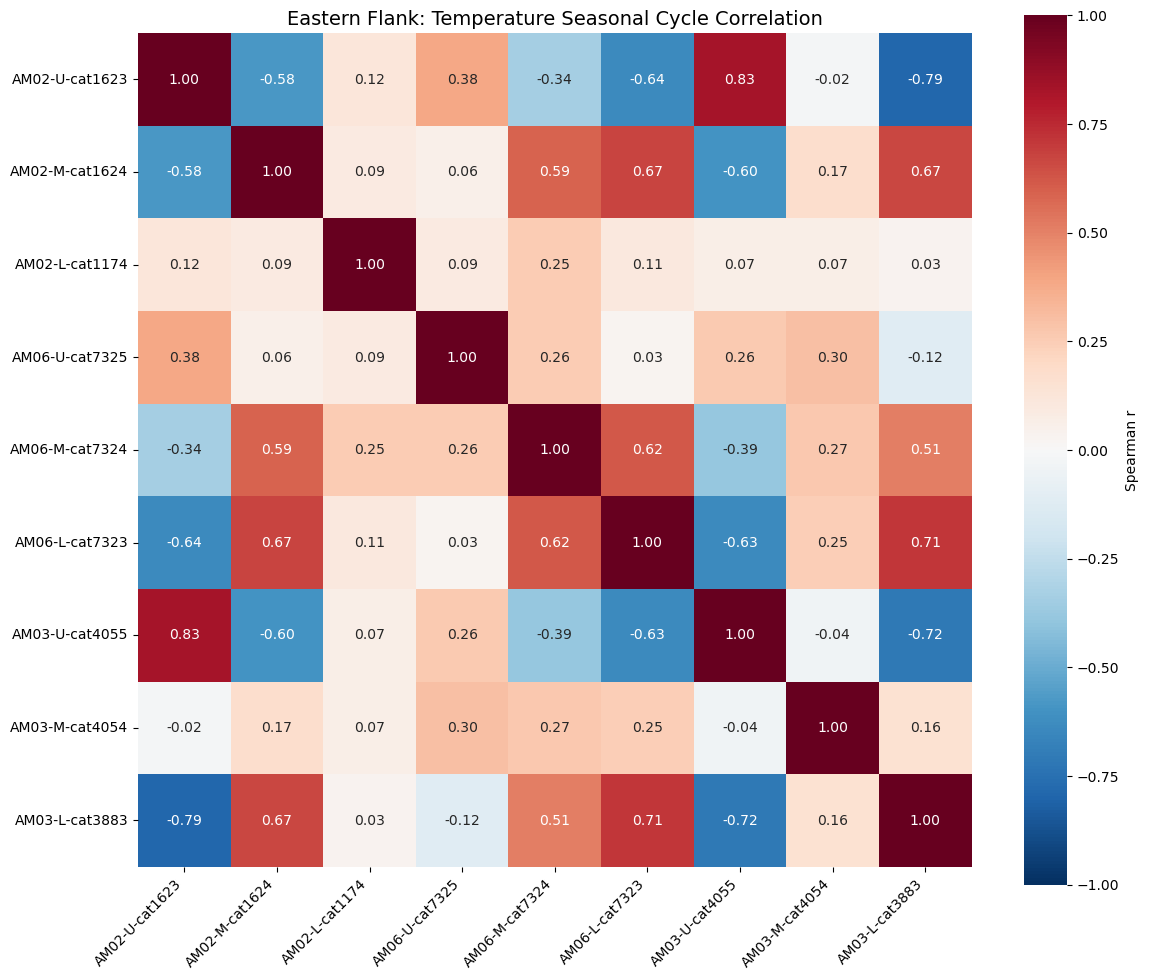

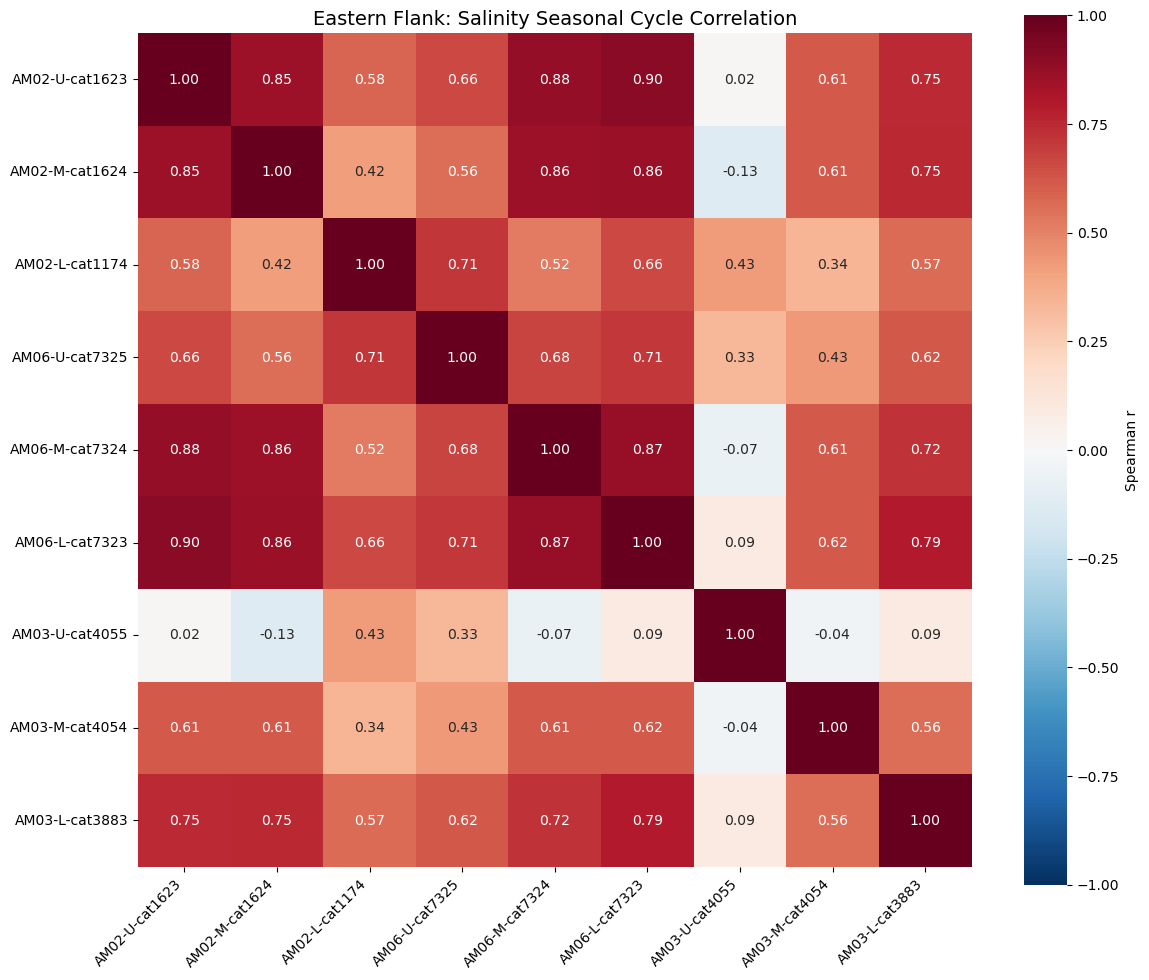

In [18]:
df = pd.read_parquet("../data/proc/03_pressure_handled.parquet")

# Specify the boreholes to investigate together
boreholes = ["AM02", "AM06", "AM03"]
corr_temp = correlation_matrix(df, boreholes=boreholes, variable="conservative_temperature", average="median")
plot_correlation_matrix(corr_temp, title="Eastern Flank: Temperature Seasonal Cycle Correlation")

corr_sal = correlation_matrix(df, boreholes=boreholes, variable="absolute_salinity", average="median")
plot_correlation_matrix(corr_sal, title="Eastern Flank: Salinity Seasonal Cycle Correlation")